# 07 — Sensitivity to violations of parallel trends (Rambachan and Roth 2023)

Uses the official R package **HonestDiD**. Workflow (from the repository root):
1. `python src/export_event_study.py`  -> exports event-study coefficients and covariance matrices
2. `Rscript src/honestdid.R`           -> runs HonestDiD, writes `output/tables/honestdid_*.csv`
3. run this notebook                   -> tables and figures for the thesis

**Setup.** Reference year 2019. Anticipation in 2020-2021 is allowed by treating 2020 onwards as
post-periods; violations are bounded using the pre-periods 2016-2018. Target parameter: average
effect 2022-2024.

* **Relative magnitudes ($\bar M$):** post-period violations of parallel trends are at most $\bar M$
  times the largest pre-period violation. The *breakdown value* is the smallest $\bar M$ at which the
  robust confidence interval includes zero.
* **Smoothness ($M$):** the differential trend may deviate from a linear extrapolation of the
  pre-trend by at most $M$ per period.

In [1]:
import os
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")
import pandas as pd
import matplotlib.pyplot as plt

TAB, FIG = Path("output/tables"), Path("output/figures")
LABEL = {"h1_ln_ci": "H1: ln(carbon intensity)", "h2_ln_emissions": "H2: ln(emissions)",
         "h2_ln_real_ci": "H2: ln(real carbon intensity)", "h2_ln_real_revenue": "H2: ln(real revenue)"}
f_rm, f_sd = TAB / "honestdid_rm.csv", TAB / "honestdid_sd.csv"
if not f_rm.exists():
    print("Run `python src/export_event_study.py` and `Rscript src/honestdid.R` first.")

## Relative magnitudes

In [2]:
if f_rm.exists():
    rm = pd.read_csv(f_rm)
    rm["excludes_zero"] = (rm.lb > 0) | (rm.ub < 0)
    def breakdown(g):
        g = g[g.method != "Original"].sort_values("Mbar")
        bad = g[~g.excludes_zero]
        return bad.Mbar.min() if len(bad) else f"> {g.Mbar.max()}"
    bd = rm.groupby("outcome").apply(breakdown).rename("breakdown_Mbar")
    bd.to_csv(TAB / "honestdid_breakdown.csv")
    display(rm.round(3))
    display(bd)

C:\Users\ial\AppData\Local\Temp\ipykernel_21920\123739479.py:8: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  bd = rm.groupby("outcome").apply(breakdown).rename("breakdown_Mbar")


,outcome,Mbar,lb,ub,method,excludes_zero
0,h1_ln_ci,NaN,-0.407,-0.053,Original,True
1,h1_ln_ci,0.00,-0.404,-0.056,C-LF,True
2,h1_ln_ci,0.25,-0.480,-0.020,C-LF,True
3,h1_ln_ci,0.50,-0.592,0.049,C-LF,False
4,h1_ln_ci,0.75,-0.719,0.168,C-LF,False
5,h1_ln_ci,1.00,-0.849,0.295,C-LF,False
6,h1_ln_ci,1.50,-1.117,0.560,C-LF,False
7,h1_ln_ci,2.00,-1.386,0.828,C-LF,False
8,h2_ln_emissions,NaN,-0.492,-0.110,Original,True
9,h2_ln_emissions,0.00,-0.490,-0.111,C-LF,True


outcome
h1_ln_ci              0.50
h2_ln_emissions       0.50
h2_ln_real_ci         0.00
h2_ln_real_revenue    0.25
Name: breakdown_Mbar, dtype: float64

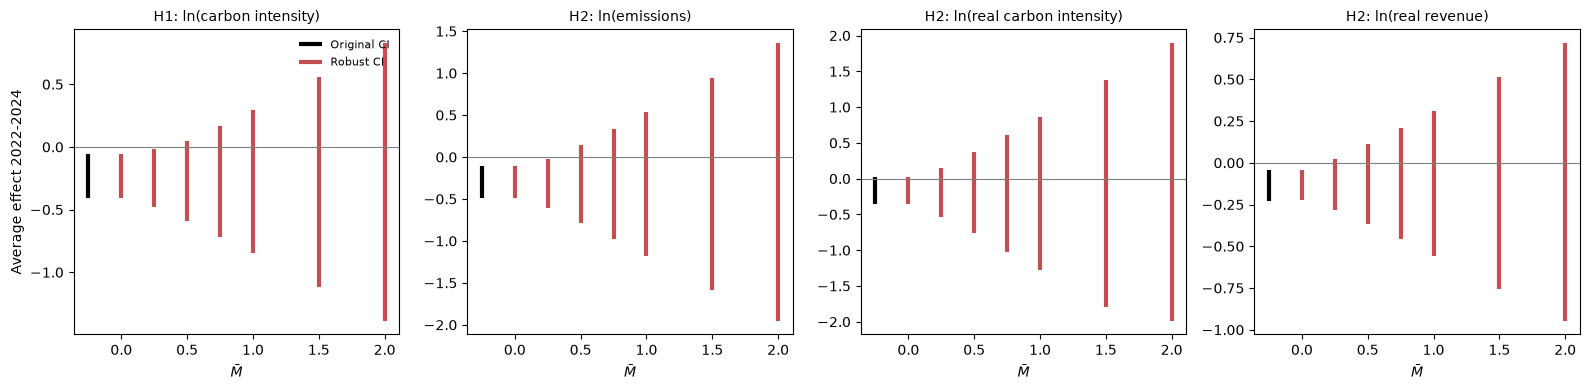

In [3]:
if f_rm.exists():
    fig, axs = plt.subplots(1, len(LABEL), figsize=(16, 4), sharey=False)
    for ax, (k, lab) in zip(axs, LABEL.items()):
        g = rm[rm.outcome == k]
        o = g[g.method == "Original"]; s = g[g.method != "Original"]
        ax.vlines(-0.25, o.lb, o.ub, color="k", lw=3, label="Original CI")
        ax.vlines(s.Mbar, s.lb, s.ub, color="#C44E52", lw=3, label="Robust CI")
        ax.axhline(0, color="grey", lw=0.8); ax.set_title(lab, fontsize=10); ax.set_xlabel(r"$\bar M$")
    axs[0].set_ylabel("Average effect 2022-2024"); axs[0].legend(frameon=False, fontsize=8)
    fig.tight_layout(); fig.savefig(FIG / "honestdid_rm.pdf"); plt.show()

## Smoothness restrictions

In [4]:
if f_sd.exists():
    sd = pd.read_csv(f_sd)
    sd["excludes_zero"] = (sd.lb > 0) | (sd.ub < 0)
    display(sd.round(3))

,outcome,M,lb,ub,method,excludes_zero
0,h1_ln_ci,0.00,-0.630,-0.045,FLCI,True
1,h1_ln_ci,0.01,-0.721,0.064,FLCI,False
2,h1_ln_ci,0.02,-0.850,0.212,FLCI,False
3,h1_ln_ci,0.05,-1.227,0.599,FLCI,False
4,h1_ln_ci,0.10,-1.842,1.199,FLCI,False
5,h2_ln_emissions,0.00,-0.568,0.070,FLCI,False
6,h2_ln_emissions,0.01,-0.680,0.145,FLCI,False
7,h2_ln_emissions,0.02,-0.836,0.266,FLCI,False
8,h2_ln_emissions,0.05,-1.264,0.603,FLCI,False
9,h2_ln_emissions,0.10,-1.931,1.158,FLCI,False
